In [13]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Check if the file is already uploaded, if not, ask for it
try:
    df = pd.read_excel("US Superstore data.xls")
except FileNotFoundError:
    uploaded = files.upload()
    # Retrieve the filename dynamically from the upload dictionary
    filename = list(uploaded.keys())[0]
    df = pd.read_excel(filename)

# Display first five rows
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [18]:
#Q2.Which states have the most sales?

top_state = sales_by_state.idxmax()
highest_sales = sales_by_state.max()

# print the first state and his sale number
print("State with the highest sales:", top_state)
print("Total sales: ${:,.2f}".format(highest_sales))

State with the highest sales: California
Total sales: $457,687.63


In [20]:
# Group by state to get sales and profit comparison
state_comparison = df.groupby('State')[['Sales', 'Profit']].sum()

# Calculate differences between the two states
sales_difference = abs(
    state_comparison.loc['New York', 'Sales'] -
    state_comparison.loc['California', 'Sales']
)

profit_difference = abs(
    state_comparison.loc['New York', 'Profit'] -
    state_comparison.loc['California', 'Profit']
)

print(f"Sales Difference: ${sales_difference:,.2f}")
print(f"Profit Difference: ${profit_difference:,.2f}")

Sales Difference: $146,811.36
Profit Difference: $2,342.84


In [21]:
# Compare sales
sales_winner = state_comparison['Sales'].idxmax()

# Compare profit
profit_winner = state_comparison['Profit'].idxmax()

print("State with higher sales:", sales_winner)
print("State with higher profit:", profit_winner)

State with higher sales: California
State with higher profit: California


In [23]:
# Filter the dataset for New York
new_york = df[df['State'] == 'New York']

# Group by customer and calculate total sales and profit
ny_customers = new_york.groupby(
    ['Customer ID', 'Customer Name']
)[['Sales', 'Profit']].sum()

# Sort customers by total sales
ny_customers = ny_customers.sort_values(
    by='Sales', ascending=False
)

# Display the top 10 customers
ny_customers.head(10)

,,Sales,Profit
Customer ID,Customer Name,,
TA-21385,Tom Ashbrook,13723.498,4599.2073
PF-19120,Peter Fuller,7678.228,543.2819
SV-20365,Seth Vernon,7359.918,1571.7964
TB-21400,Tom Boeckenhauer,6999.960,2239.9872
GT-14710,Greg Tran,6712.744,774.7935
TS-21370,Todd Sumrall,6492.314,1574.9714
KD-16270,Karen Daniels,6241.282,2283.0463
KD-16495,Keith Dawkins,5854.194,2510.8903
LW-17215,Luke Weiss,5048.186,773.1004


In [24]:
outstanding_customer = ny_customers.iloc[0]

print("Outstanding Customer:", ny_customers.index[0][1])
print("Total Sales: ${:,.2f}".format(outstanding_customer['Sales']))
print("Total Profit: ${:,.2f}".format(outstanding_customer['Profit']))

Outstanding Customer: Tom Ashbrook
Total Sales: $13,723.50
Total Profit: $4,599.21


In [26]:
# Define profit_by_state from the existing state_comparison DataFrame
profit_by_state = state_comparison['Profit']

# Most profitable state
most_profitable = profit_by_state.idxmax()
highest_profit = profit_by_state.max()

# Least profitable state
least_profitable = profit_by_state.idxmin()
lowest_profit = profit_by_state.min()

print("Most Profitable State:", most_profitable)
print("Highest Profit: ${:,.2f}".format(highest_profit))

print("\nLeast Profitable State:", least_profitable)
print("Lowest Profit: ${:,.2f}".format(lowest_profit))

Most Profitable State: California
Highest Profit: $76,381.39

Least Profitable State: Texas
Lowest Profit: $-25,729.36


In [28]:
# Calculate total profit per customer across the dataset
customer_profit = df.groupby(['Customer ID', 'Customer Name'])[['Profit']].sum().reset_index()

# Sort customers by profit descending
customer_profit = customer_profit.sort_values(by='Profit', ascending=False).reset_index(drop=True)

# Calculate cumulative profit and cumulative profit percentage
customer_profit['Cumulative Profit'] = customer_profit['Profit'].cumsum()
total_overall_profit = customer_profit['Profit'].sum()
customer_profit['Cumulative Profit (%)'] = (customer_profit['Cumulative Profit'] / total_overall_profit) * 100

# Define total number of customers
total_customers = len(customer_profit)

# Find the number of customers needed to generate 80% of profit
customers_for_80_profit = (
    customer_profit['Cumulative Profit (%)'] >= 80
).idxmax() + 1

# Calculate percentage of customers
customer_percentage = (
    customers_for_80_profit / total_customers
) * 100

# Calculate profit contribution
profit_percentage = (
    customer_profit.iloc[customers_for_80_profit - 1]
    ['Cumulative Profit (%)']
)

print("Total number of customers:", total_customers)

print("Customers contributing to 80% of profit:",
      customers_for_80_profit)

print("Percentage of customers: {:.2f}%".format(
    customer_percentage
))

print("Their cumulative profit contribution: {:.2f}%".format(
    profit_percentage
))

# Check the Pareto principle
if customer_percentage <= 20:
    print("\nConclusion: The Pareto Principle is supported.")
else:
    print("\nConclusion: The Pareto Principle is not strictly supported.")

Total number of customers: 793
Customers contributing to 80% of profit: 153
Percentage of customers: 19.29%
Their cumulative profit contribution: 80.21%

Conclusion: The Pareto Principle is supported.


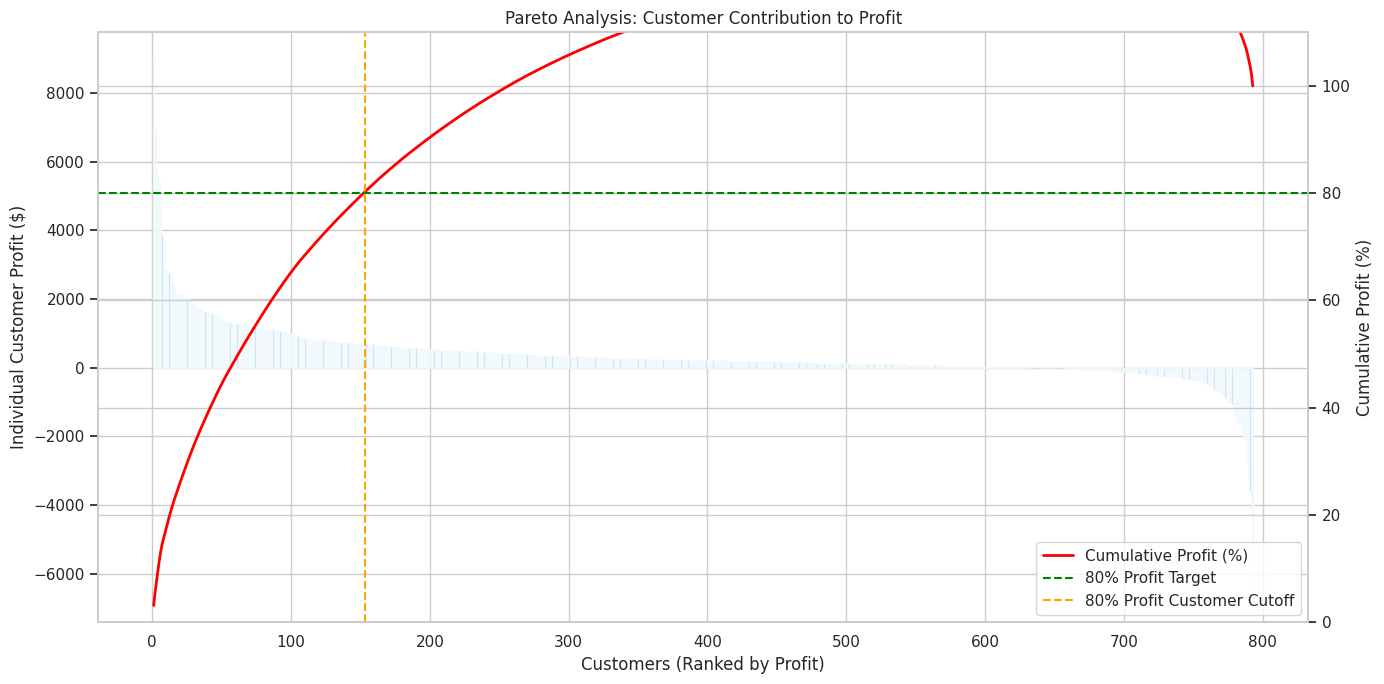

In [29]:
fig, ax1 = plt.subplots(figsize=(14, 7))

# Customer rank
customer_rank = np.arange(1, total_customers + 1)

# Plot individual customer profits
ax1.bar(
    customer_rank,
    customer_profit['Profit'],
    color='skyblue',
    alpha=0.7
)

ax1.set_xlabel('Customers (Ranked by Profit)')
ax1.set_ylabel('Individual Customer Profit ($)')
ax1.set_title('Pareto Analysis: Customer Contribution to Profit')

# Second axis for cumulative profit percentage
ax2 = ax1.twinx()

ax2.plot(
    customer_rank,
    customer_profit['Cumulative Profit (%)'],
    color='red',
    linewidth=2,
    label='Cumulative Profit (%)'
)

ax2.axhline(
    80,
    color='green',
    linestyle='--',
    label='80% Profit Target'
)

ax2.axvline(
    customers_for_80_profit,
    color='orange',
    linestyle='--',
    label='80% Profit Customer Cutoff'
)

ax2.set_ylabel('Cumulative Profit (%)')
ax2.set_ylim(0, 110)

ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()

In [32]:
# Define total_profit using the variable from the previous cell
total_profit = total_overall_profit

# Calculate the top 20% of customers
top_20_count = int(np.ceil(total_customers * 0.20))

# Select the top 20%
top_20_customers = customer_profit.head(top_20_count)

# Calculate their profit contribution
top_20_profit = top_20_customers['Profit'].sum()

top_20_percentage = (
top_20_profit / total_profit
) * 100

print("Top 20% of customers:", top_20_count)

print("Total profit from top 20%: ${:,.2f}".format(
    top_20_profit
))

print("Percentage of total profit: {:.2f}%".format(
    top_20_percentage
))

display(top_20_customers)

Top 20% of customers: 159
Total profit from top 20%: $233,885.47
Percentage of total profit: 81.66%


,Customer ID,Customer Name,Profit,Cumulative Profit,Cumulative Profit (%)
0,TC-20980,Tamara Chand,8981.3239,8981.3239,3.135970
1,RB-19360,Raymond Buch,6976.0959,15957.4198,5.571783
2,SC-20095,Sanjit Chand,5757.4119,21714.8317,7.582073
3,HL-15040,Hunter Lopez,5622.4292,27337.2609,9.545232
4,AB-10105,Adrian Barton,5444.8055,32782.0664,11.446371
...,...,...,...,...,...
154,FH-14350,Fred Harton,706.2890,231119.1147,80.698854
155,RW-19630,Rob Williams,698.8325,231817.9472,80.942862
156,MC-17845,Michael Chen,698.4174,232516.3646,81.186726
157,ML-17395,Marina Lichtenstein,684.9162,233201.2808,81.425875


In [34]:
# Calculate city performance from the main DataFrame
city_performance = df.groupby('City')[['Sales', 'Profit']].sum()

top20_sales = city_performance.sort_values(
    by='Sales',
    ascending=False
).head(20)

print("Top 20 Cities by Sales:")
display(top20_sales)

Top 20 Cities by Sales:


,Sales,Profit
City,,
New York City,256368.1610,62036.9837
Los Angeles,175851.3410,30440.7579
Seattle,119540.7420,29156.0967
San Francisco,112669.0920,17507.3854
Philadelphia,109077.0130,-13837.7674
Houston,64504.7604,-10153.5485
Chicago,48539.5410,-6654.5688
San Diego,47521.0290,6377.1960
Jacksonville,44713.1830,-2323.8350


In [35]:
top20_profit = city_performance.sort_values(
    by='Profit',
    ascending=False
).head(20)

print("Top 20 Cities by Profit:")
display(top20_profit)

Top 20 Cities by Profit:


,Sales,Profit
City,,
New York City,256368.161,62036.9837
Los Angeles,175851.341,30440.7579
Seattle,119540.742,29156.0967
San Francisco,112669.092,17507.3854
Detroit,42446.944,13181.7908
Lafayette,25036.200,10018.3876
Jackson,24963.858,7581.6828
Atlanta,17197.840,6993.6629
Minneapolis,16870.540,6824.5846


In [36]:
loss_making_cities = city_performance[
    city_performance['Profit'] < 0
].sort_values(by='Profit')

print("Cities Operating at a Loss:")
display(loss_making_cities)

Cities Operating at a Loss:


,Sales,Profit
City,,
Philadelphia,109077.0130,-13837.7674
Houston,64504.7604,-10153.5485
San Antonio,21843.5280,-7299.0502
Lancaster,9891.4640,-7239.0684
Chicago,48539.5410,-6654.5688
...,...,...
Ormond Beach,2.8080,-1.9656
Pensacola,2.2140,-1.4760
Elyria,1.8240,-1.3984


In [37]:
# Group sales by customer
customer_sales = df.groupby('Customer Name')['Sales'].sum().reset_index()

# Sort sales in descending order and select the top 20
top20_customers = customer_sales.sort_values(
    by='Sales',
    ascending=False
).head(20)

# Display results
print("Top 20 Customers by Sales:")
display(top20_customers)

Top 20 Customers by Sales:


,Customer Name,Sales
686,Sean Miller,25043.050
730,Tamara Chand,19052.218
622,Raymond Buch,15117.339
757,Tom Ashbrook,14595.620
6,Adrian Barton,14473.571
441,Ken Lonsdale,14175.229
671,Sanjit Chand,14142.334
334,Hunter Lopez,12873.298
672,Sanjit Engle,12209.438
156,Christopher Conant,12129.072


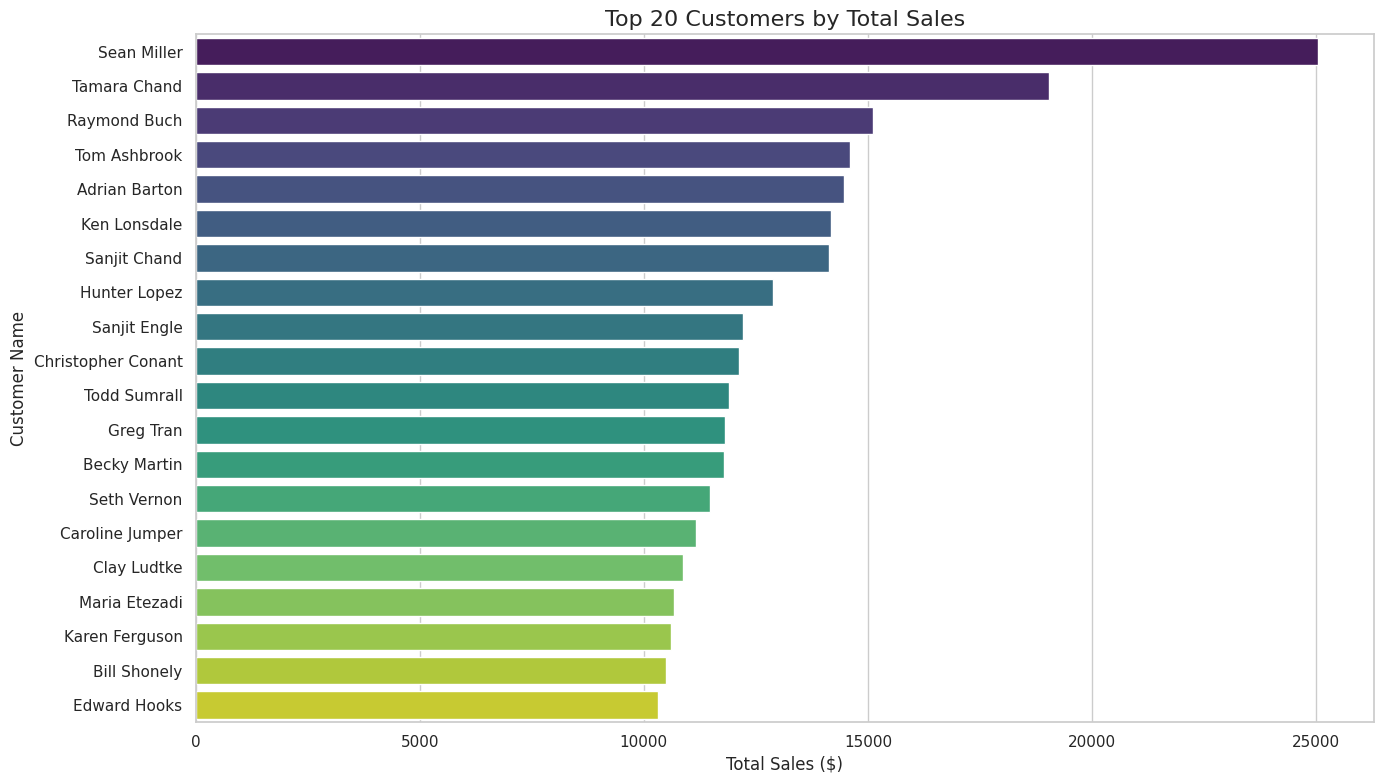

In [38]:
plt.figure(figsize=(14, 8))

sns.barplot(
    data=top20_customers,
    x='Sales',
    y='Customer Name',
    hue='Customer Name',
    palette='viridis',
    legend=False
)

plt.title('Top 20 Customers by Total Sales', fontsize=16)
plt.xlabel('Total Sales ($)')
plt.ylabel('Customer Name')

plt.tight_layout()
plt.show()

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate total sales for each customer
customer_sales = (
    df.groupby('Customer Name')['Sales']
    .sum()
    .reset_index()
)

# Sort customers by sales in descending order
customer_sales = customer_sales.sort_values(
    by='Sales',
    ascending=False
).reset_index(drop=True)

# Calculate cumulative sales
customer_sales['Cumulative Sales'] = customer_sales['Sales'].cumsum()

# Calculate cumulative percentage
total_sales = customer_sales['Sales'].sum()

customer_sales['Cumulative Sales (%)'] = (
    customer_sales['Cumulative Sales'] / total_sales
) * 100

# Calculate cumulative percentage of customers
customer_sales['Cumulative Customers (%)'] = (
    (np.arange(1, len(customer_sales) + 1) /
     len(customer_sales)) * 100
)

display(customer_sales.head(10))

,Customer Name,Sales,Cumulative Sales,Cumulative Sales (%),Cumulative Customers (%)
0,Sean Miller,25043.050,25043.050,1.090155,0.126103
1,Tamara Chand,19052.218,44095.268,1.919522,0.252207
2,Raymond Buch,15117.339,59212.607,2.577598,0.378310
3,Tom Ashbrook,14595.620,73808.227,3.212964,0.504414
4,Adrian Barton,14473.571,88281.798,3.843016,0.630517
5,Ken Lonsdale,14175.229,102457.027,4.460081,0.756620
6,Sanjit Chand,14142.334,116599.361,5.075715,0.882724
7,Hunter Lopez,12873.298,129472.659,5.636105,1.008827
8,Sanjit Engle,12209.438,141682.097,6.167597,1.134931
9,Christopher Conant,12129.072,153811.169,6.695591,1.261034


In [41]:
# Number of customers
total_customers = len(customer_sales)

# Number representing the top 20% of customers
top_20_percent_count = int(np.ceil(total_customers * 0.20))

# Sales generated by the top 20% of customers
top_20_customers_sales = customer_sales.head(
    top_20_percent_count
)['Sales'].sum()

# Calculate percentage of total sales
top_20_sales_percentage = (
    top_20_customers_sales / total_sales
) * 100

print("Total number of customers:", total_customers)

print("Top 20% of customers:", top_20_percent_count)

print(
    "Sales generated by the top 20%: "
    f"${top_20_customers_sales:,.2f}"
)

print(
    f"Percentage of total sales: "
    f"{top_20_sales_percentage:.2f}%"
)

Total number of customers: 793
Top 20% of customers: 159
Sales generated by the top 20%: $1,106,064.33
Percentage of total sales: 48.15%


In [42]:
# Aggregate sales and profit by state
state_performance = df.groupby('State').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()

# Calculate profit margin
state_performance['Profit Margin (%)'] = (
    state_performance['Profit'] /
    state_performance['Sales']
) * 100

# Sort by sales
state_performance = state_performance.sort_values(
    by='Sales',
    ascending=False
)

display(state_performance.head(20))

,State,Sales,Profit,Profit Margin (%)
3,California,457687.6315,76381.3871,16.688541
30,New York,310876.2710,74038.5486,23.816082
41,Texas,170188.0458,-25729.3563,-15.118192
45,Washington,138641.2700,33402.6517,24.092863
36,Pennsylvania,116511.9140,-15559.9603,-13.354823
8,Florida,89473.7080,-3399.3017,-3.799219
11,Illinois,80166.1010,-12607.8870,-15.727205
33,Ohio,78258.1360,-16971.3766,-21.686405
20,Michigan,76269.6140,24463.1876,32.074618
44,Virginia,70636.7200,18597.9504,26.329012


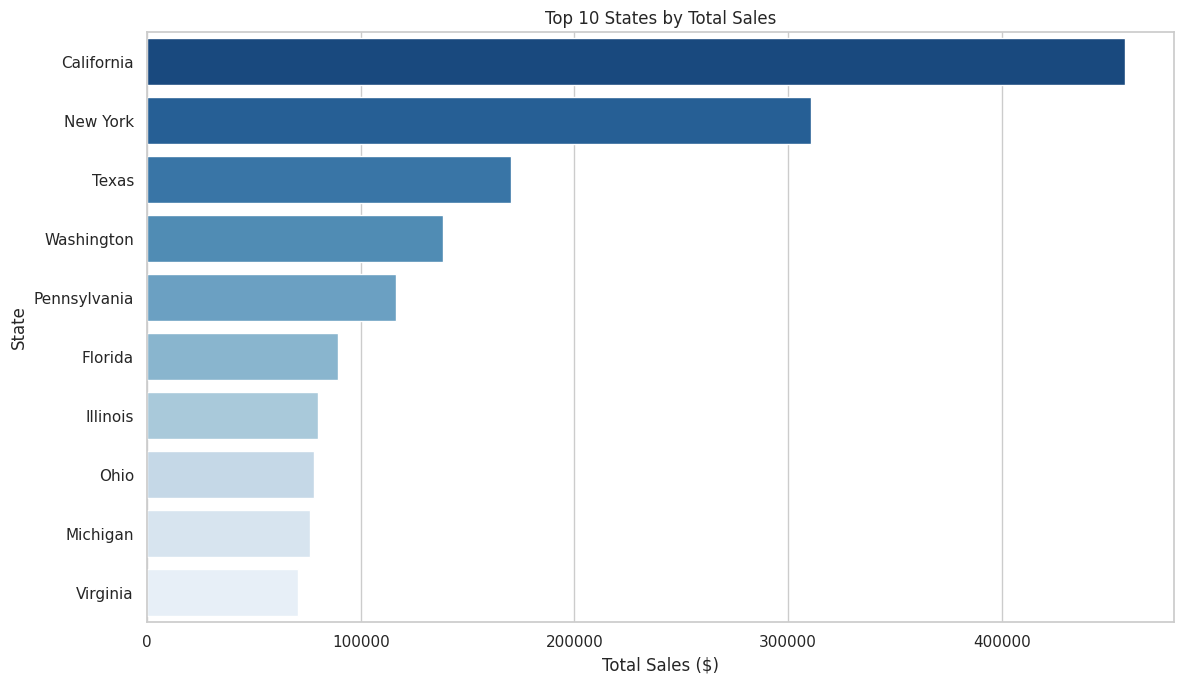

In [43]:
top_states_sales = state_performance.nlargest(10, 'Sales')

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_states_sales,
    x='Sales',
    y='State',
    hue='State',
    palette='Blues_r',
    legend=False
)

plt.title('Top 10 States by Total Sales')
plt.xlabel('Total Sales ($)')
plt.ylabel('State')
plt.tight_layout()
plt.show()

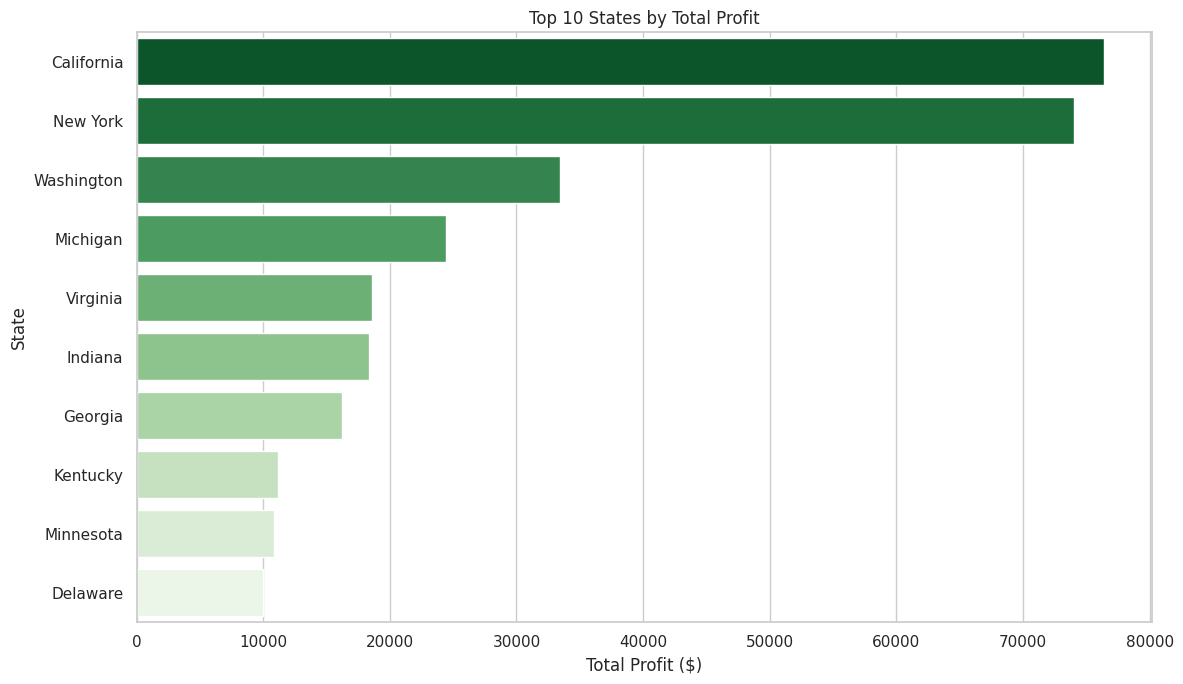

In [44]:
top_states_profit = state_performance.nlargest(10, 'Profit')

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_states_profit,
    x='Profit',
    y='State',
    hue='State',
    palette='Greens_r',
    legend=False
)

plt.title('Top 10 States by Total Profit')
plt.xlabel('Total Profit ($)')
plt.ylabel('State')
plt.tight_layout()
plt.show()

In [45]:
# Aggregate sales and profit by state and city
city_performance = df.groupby(
    ['State', 'City']
).agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()

# Calculate profit margin
city_performance['Profit Margin (%)'] = (
    city_performance['Profit'] /
    city_performance['Sales']
) * 100

# Top 20 cities by sales
top_cities_sales = city_performance.nlargest(20, 'Sales')

# Top 20 cities by profit
top_cities_profit = city_performance.nlargest(20, 'Profit')

print("Top 20 Cities by Sales")
display(top_cities_sales)

print("Top 20 Cities by Profit")
display(top_cities_profit)

Top 20 Cities by Sales


,State,City,Sales,Profit,Profit Margin (%)
389,New York,New York City,256368.1610,62036.9837,24.198396
63,California,Los Angeles,175851.3410,30440.7579,17.310507
586,Washington,Seattle,119540.7420,29156.0967,24.390092
90,California,San Francisco,112669.0920,17507.3854,15.538765
463,Pennsylvania,Philadelphia,109077.0130,-13837.7674,-12.686236
521,Texas,Houston,64504.7604,-10153.5485,-15.740774
201,Illinois,Chicago,48539.5410,-6654.5688,-13.709583
89,California,San Diego,47521.0290,6377.1960,13.419735
295,Michigan,Detroit,42446.9440,13181.7908,31.054746
153,Florida,Jacksonville,39133.3280,-2445.6608,-6.249560


Top 20 Cities by Profit


,State,City,Sales,Profit,Profit Margin (%)
389,New York,New York City,256368.161,62036.9837,24.198396
63,California,Los Angeles,175851.341,30440.7579,17.310507
586,Washington,Seattle,119540.742,29156.0967,24.390092
90,California,San Francisco,112669.092,17507.3854,15.538765
295,Michigan,Detroit,42446.944,13181.7908,31.054746
233,Indiana,Lafayette,19630.450,8976.0973,45.725377
138,Delaware,Newark,20448.050,8086.1715,39.544952
178,Georgia,Atlanta,17197.840,6993.6629,40.665938
318,Minnesota,Minneapolis,16870.540,6824.5846,40.452674
89,California,San Diego,47521.029,6377.1960,13.419735


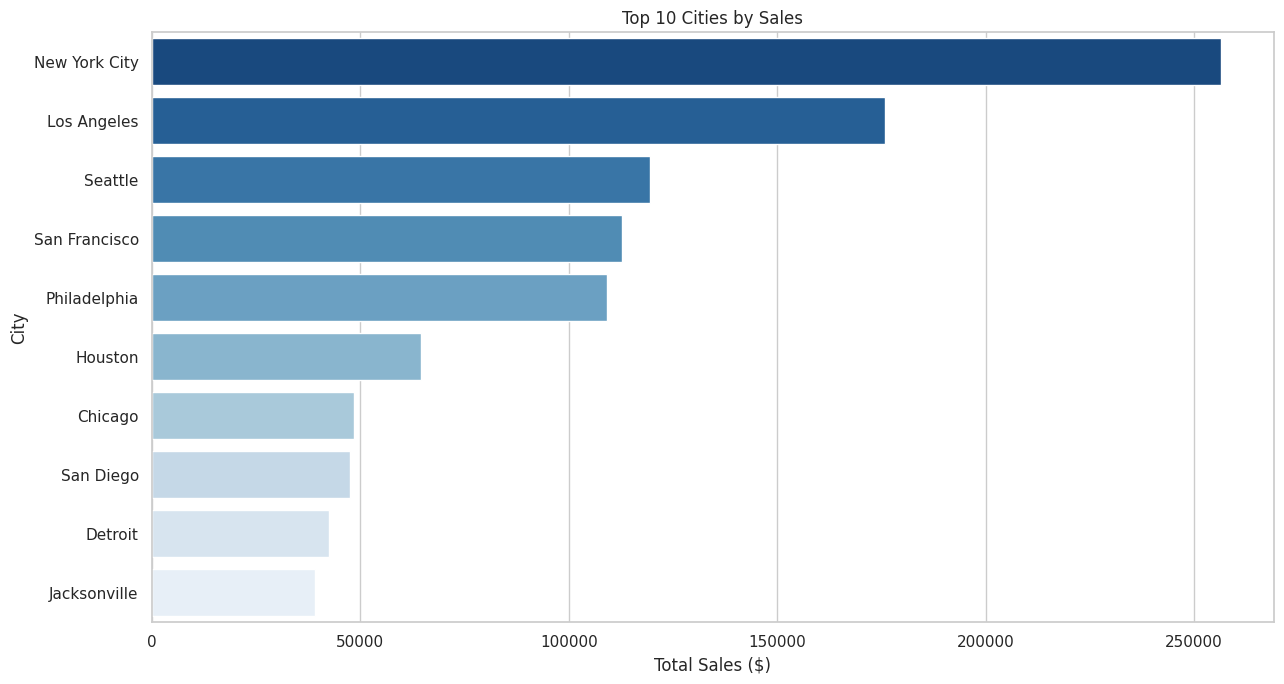

In [46]:
top10_cities = city_performance.nlargest(10, 'Sales')

plt.figure(figsize=(13, 7))

sns.barplot(
    data=top10_cities,
    x='Sales',
    y='City',
    hue='City',
    palette='Blues_r',
    legend=False
)

plt.title('Top 10 Cities by Sales')
plt.xlabel('Total Sales ($)')
plt.ylabel('City')
plt.tight_layout()
plt.show()

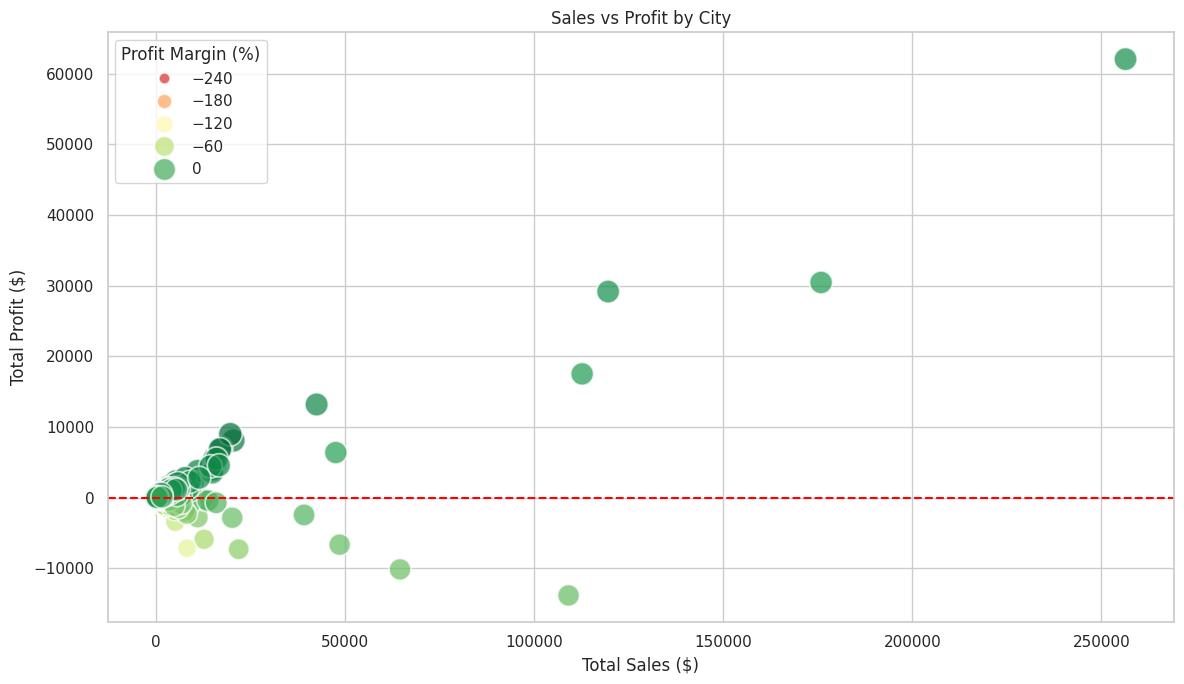

In [47]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=city_performance,
    x='Sales',
    y='Profit',
    size='Profit Margin (%)',
    hue='Profit Margin (%)',
    sizes=(40, 300),
    palette='RdYlGn',
    alpha=0.7
)

plt.axhline(0, color='red', linestyle='--')

plt.title('Sales vs Profit by City')
plt.xlabel('Total Sales ($)')
plt.ylabel('Total Profit ($)')

plt.tight_layout()
plt.show()

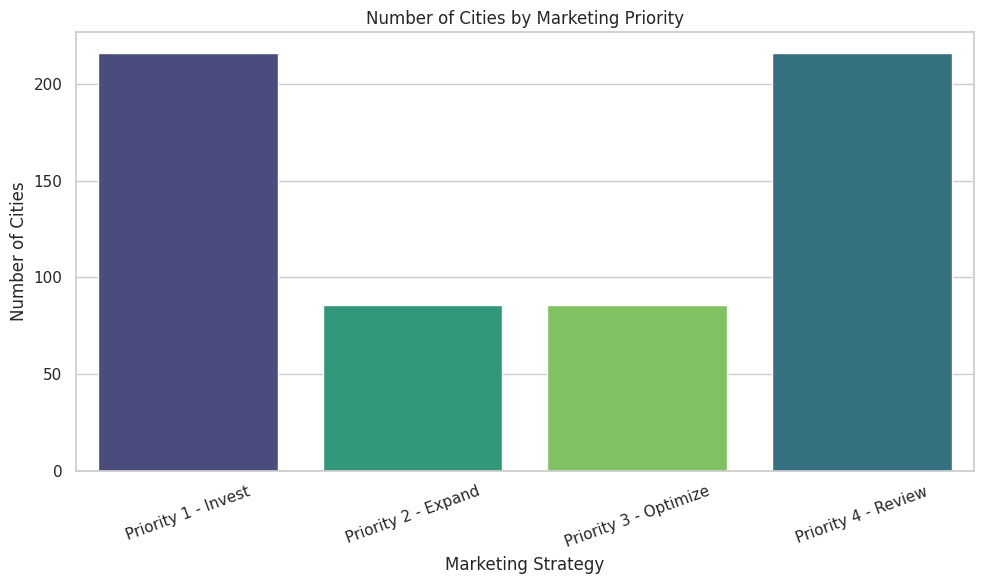

In [51]:
# Define thresholds for categorization
sales_threshold = city_performance['Sales'].median()
profit_threshold = city_performance['Profit'].median()

# Categorize cities into Marketing Priorities
def assign_priority(row):
    if row['Sales'] >= sales_threshold and row['Profit'] >= profit_threshold:
        return 'Priority 1 - Invest'
    elif row['Sales'] >= sales_threshold and row['Profit'] < profit_threshold:
        return 'Priority 2 - Expand'
    elif row['Sales'] < sales_threshold and row['Profit'] >= profit_threshold:
        return 'Priority 3 - Optimize'
    else:
        return 'Priority 4 - Review'

city_performance['Marketing Priority'] = city_performance.apply(assign_priority, axis=1)

# Plot the countplot
plt.figure(figsize=(10, 6))

sns.countplot(
    data=city_performance,
    x='Marketing Priority',
    hue='Marketing Priority',
    palette='viridis',
    order=[
        'Priority 1 - Invest',
        'Priority 2 - Expand',
        'Priority 3 - Optimize',
        'Priority 4 - Review'
    ],
    legend=False
)

plt.title('Number of Cities by Marketing Priority')
plt.xlabel('Marketing Strategy')
plt.ylabel('Number of Cities')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()